# 01 — Exploratory analysis of PM2.5 and weather in Lahore (2019–2026)

**Project:** Lahore Air Intelligence — AI-Driven Analysis and Prediction of Air Pollution in Lahore, Pakistan

**Research question:** How do seasonal and meteorological conditions influence PM2.5 concentrations in Lahore, and can machine learning predict short-term changes?

This notebook answers the descriptive part of the question:
1. How has PM2.5 in Lahore changed over recent years?
2. Which months and seasons are the worst?
3. How does PM2.5 relate to temperature, wind, rain, humidity and the boundary-layer height (an inversion / "lid" proxy)?
4. Does the crop-fire season line up with the pollution peak?

**Important limitation:** correlations between weather and PM2.5 tell us about *conditions that trap or disperse pollution*. They do **not** tell us which emission source is the largest. Source contributions need emission inventories or chemical source-apportionment studies (see `research/literature_review.md`).

Data: `data/processed/lahore_daily_merged.csv`, built by `src/fetch_data.py` and `src/build_dataset.py`. See `data/README.md` for sources and caveats.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = os.path.abspath("..")
VIS = os.path.join(ROOT, "visualizations")
os.makedirs(VIS, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
WHO_24H, WHO_ANNUAL = 15, 5   # WHO 2021 guideline values, µg/m³

df = pd.read_csv(os.path.join(ROOT, "data/processed/lahore_daily_merged.csv"), parse_dates=["date"]).set_index("date")
pm = df["pm25_consulate"]
print(df.shape)
df.notna().sum().to_frame("non-missing days")

(2876, 24)


,non-missing days
pm25_consulate,1456
pm25_clarity_sensor,642
pm25_cams_model,1563
pm10_cams_model,1563
co_cams_model,1563
no2_cams_model,1563
dust_cams_model,1563
temp_mean_c,2876
temp_min_c,2876
temp_max_c,2876


## 1. Data coverage
The main measured series is the **US Consulate Lahore reference monitor** (via the OpenAQ archive). It runs from May 2019 to March 2025 but has gaps. A low-cost **Clarity sensor** (Nov 2023 – Aug 2026) and the **CAMS model** (Aug 2022 – Nov 2026) fill some of the gaps, but they are not equally reliable, so I keep them as separate columns.

In [2]:
cov = pd.DataFrame({c: df[c].notna().groupby(df.index.year).sum()
                    for c in ["pm25_consulate", "pm25_clarity_sensor", "pm25_cams_model", "temp_mean_c", "blh_mean_m", "fires_punjab_region_total"]})
cov

,pm25_consulate,pm25_clarity_sensor,pm25_cams_model,temp_mean_c,blh_mean_m,fires_punjab_region_total
date,,,,,,
2019,209,0,0,365,365,365
2020,321,0,0,366,366,366
2021,227,0,0,365,365,365
2022,99,0,148,365,365,365
2023,290,32,365,365,365,365
2024,263,319,366,366,184,366
2025,47,207,365,365,365,365
2026,0,84,319,319,319,0


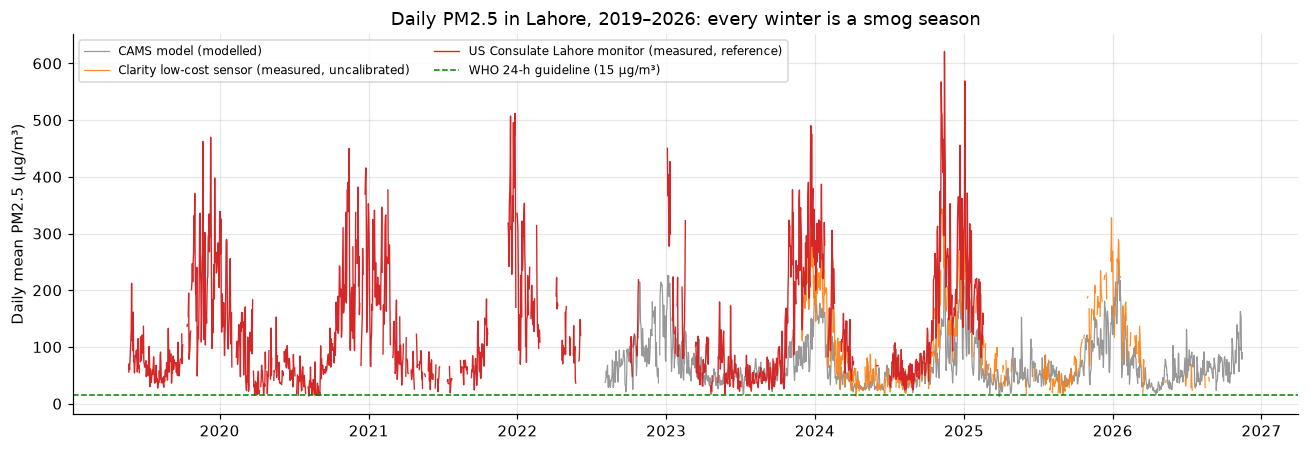

In [3]:
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(df.index, df.pm25_cams_model, color="tab:gray", lw=0.8, alpha=0.8, label="CAMS model (modelled)")
ax.plot(df.index, df.pm25_clarity_sensor, color="tab:orange", lw=0.8, alpha=0.9, label="Clarity low-cost sensor (measured, uncalibrated)")
ax.plot(df.index, pm, color="tab:red", lw=0.9, label="US Consulate Lahore monitor (measured, reference)")
ax.axhline(WHO_24H, color="green", ls="--", lw=1, label=f"WHO 24-h guideline ({WHO_24H} µg/m³)")
ax.set_ylabel("Daily mean PM2.5 (µg/m³)")
ax.set_title("Daily PM2.5 in Lahore, 2019–2026: every winter is a smog season")
ax.legend(loc="upper left", fontsize=8, ncol=2)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout(); fig.savefig(os.path.join(VIS, "fig01_daily_pm25_timeseries.png")); plt.show()

## 2. How bad is it? Headline statistics (US Consulate monitor)

In [4]:
# The merged file is a full daily calendar, so pm contains many missing days.
# Compare thresholds on valid measurements only. Counting a missing day as
# "not above the guideline" made the first draft report 50% instead of 99.5%.
pm_valid = pm.dropna()
stats = {
    "valid days": int(pm_valid.shape[0]),
    "period": f"{pm_valid.index.min().date()} to {pm_valid.index.max().date()}",
    "mean of all valid days (µg/m³)": round(pm_valid.mean(), 1),
    "median (µg/m³)": round(pm_valid.median(), 1),
    "% of days above WHO 24-h guideline (15)": round(100 * (pm_valid > WHO_24H).mean(), 1),
    "% of days above 55.4 (US AQI 'Unhealthy' and worse)": round(100 * (pm_valid > 55.4).mean(), 1),
    "% of days above 150.4 (US AQI 'Very Unhealthy' and worse)": round(100 * (pm_valid > 150.4).mean(), 1),
    "% of days above 250.4 (US AQI 'Hazardous')": round(100 * (pm_valid > 250.4).mean(), 1),
    "worst day": f"{pm_valid.idxmax().date()} ({pm_valid.max():.0f} µg/m³)",
    "times WHO 24-h guideline on worst day": round(pm_valid.max() / WHO_24H, 1),
}
pd.Series(stats)

valid days                                                                       1456
period                                                       2019-05-23 to 2025-02-17
mean of all valid days (µg/m³)                                                  131.8
median (µg/m³)                                                                   92.6
% of days above WHO 24-h guideline (15)                                          99.5
% of days above 55.4 (US AQI 'Unhealthy' and worse)                              74.7
% of days above 150.4 (US AQI 'Very Unhealthy' and worse)                        31.9
% of days above 250.4 (US AQI 'Hazardous')                                       14.2
worst day                                                      2024-11-14 (621 µg/m³)
times WHO 24-h guideline on worst day                                            41.4
dtype: object

## 3. Year-to-year: a fair comparison
Calendar-year averages are misleading here because the monitor missed different months in different years (e.g. 2022 is missing most of the summer, and 2025 only has January–March, which are winter months). A fairer comparison is the **core smog season (November–January)** of each winter, shown with the number of valid days.

In [5]:
def season_label(ts):
    y = ts.year if ts.month >= 11 else ts.year - 1
    return f"{y}-{str(y+1)[-2:]}"
core = df[df.index.month.isin([11, 12, 1])].copy()
core["winter"] = [season_label(t) for t in core.index]
w = core.groupby("winter").agg(consulate_mean=("pm25_consulate", "mean"), consulate_days=("pm25_consulate", "count"),
                               cams_mean=("pm25_cams_model", "mean"), cams_days=("pm25_cams_model", "count"),
                               clarity_mean=("pm25_clarity_sensor", "mean"), clarity_days=("pm25_clarity_sensor", "count")).round(1)
w = w[w.index >= "2019-20"]
w

,consulate_mean,consulate_days,cams_mean,cams_days,clarity_mean,clarity_days
winter,,,,,,
2019-20,212.3,92,NaN,0,NaN,0
2020-21,224.0,84,NaN,0,NaN,0
2021-22,267.8,51,NaN,0,NaN,0
2022-23,228.8,20,122.1,90,NaN,0
2023-24,269.3,86,114.4,92,210.4,63
2024-25,264.6,91,123.2,92,198.7,75
2025-26,NaN,0,124.7,92,189.1,64
2026-27,NaN,0,111.4,15,NaN,0


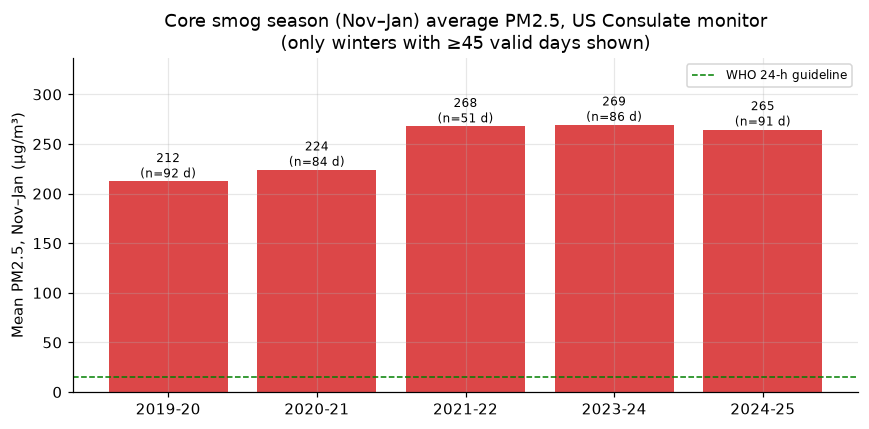

In [6]:
plot_w = w[w.consulate_days >= 45]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(plot_w.index, plot_w.consulate_mean, color="tab:red", alpha=0.85)
for b, n in zip(bars, plot_w.consulate_days):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 4, f"{b.get_height():.0f}\n(n={n} d)", ha="center", fontsize=8)
ax.axhline(WHO_24H, color="green", ls="--", lw=1, label="WHO 24-h guideline")
ax.set_ylabel("Mean PM2.5, Nov–Jan (µg/m³)")
ax.set_title("Core smog season (Nov–Jan) average PM2.5, US Consulate monitor\n(only winters with ≥45 valid days shown)")
ax.set_ylim(0, plot_w.consulate_mean.max() * 1.25); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(VIS, "fig02_winter_season_comparison.png")); plt.show()

## 4. Which months and seasons are worst?

In [7]:
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
monthly = pm.groupby(pm.index.month).agg(["mean", "median", "count"]).round(1)
monthly.index = months
season_map = {12:"Winter (Dec–Feb)",1:"Winter (Dec–Feb)",2:"Winter (Dec–Feb)",3:"Spring / pre-monsoon (Mar–May)",4:"Spring / pre-monsoon (Mar–May)",5:"Spring / pre-monsoon (Mar–May)",
              6:"Monsoon (Jun–Sep)",7:"Monsoon (Jun–Sep)",8:"Monsoon (Jun–Sep)",9:"Monsoon (Jun–Sep)",10:"Post-monsoon (Oct–Nov)",11:"Post-monsoon (Oct–Nov)"}
seasonal = pm.groupby(pm.index.month.map(season_map)).agg(["mean", "median", "count"]).round(1).sort_values("mean", ascending=False)
display(monthly); display(seasonal)
print("Ratio of worst month mean to cleanest month mean:", round(monthly["mean"].max() / monthly["mean"].min(), 1))

,mean,median,count
Jan,219.7,218.4,167
Feb,167.3,151.0,102
Mar,85.8,87.1,97
Apr,70.6,59.2,85
May,78.4,71.8,87
Jun,68.0,64.2,114
Jul,52.1,48.7,119
Aug,46.3,42.9,140
Sep,64.3,63.3,137
Oct,136.2,116.9,151


,mean,median,count
date,,,
Winter (Dec–Feb),222.9,209.7,407
Post-monsoon (Oct–Nov),187.9,155.9,270
Spring / pre-monsoon (Mar–May),78.6,70.6,269
Monsoon (Jun–Sep),57.4,54.2,510


Ratio of worst month mean to cleanest month mean: 5.8


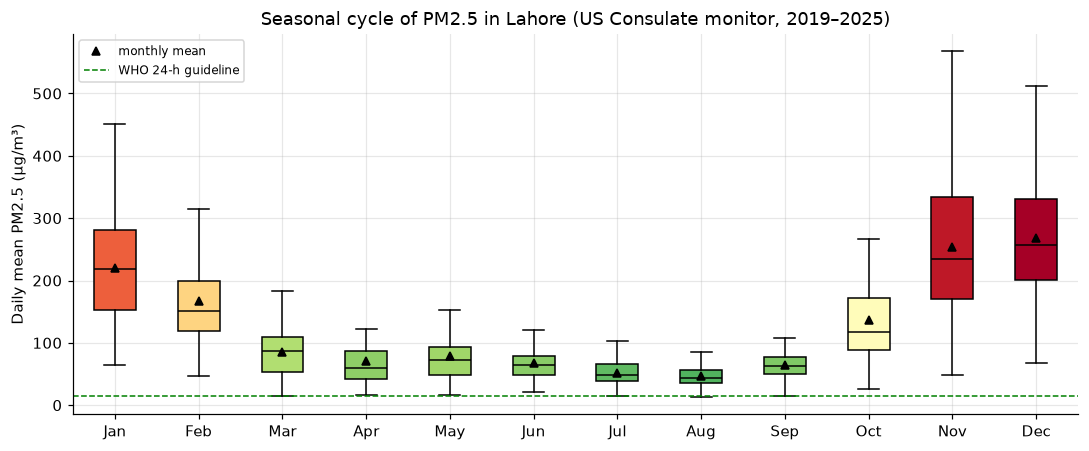

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.2))
data = [pm[pm.index.month == m].dropna().values for m in range(1, 13)]
bp = ax.boxplot(data, tick_labels=months, showfliers=False, patch_artist=True, medianprops=dict(color="black"))
cols = plt.cm.RdYlGn_r(np.clip(monthly["mean"].values / monthly["mean"].max(), 0, 1))
for patch, c in zip(bp["boxes"], cols):
    patch.set_facecolor(c)
ax.plot(range(1, 13), monthly["mean"].values, "k^", ms=5, label="monthly mean")
ax.axhline(WHO_24H, color="green", ls="--", lw=1, label="WHO 24-h guideline")
ax.set_ylabel("Daily mean PM2.5 (µg/m³)")
ax.set_title("Seasonal cycle of PM2.5 in Lahore (US Consulate monitor, 2019–2025)")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(VIS, "fig03_monthly_seasonal_cycle.png")); plt.show()

## 5. Time of day: the night-time "lid"
Using the hourly monitor data, PM2.5 in winter peaks at night and early morning, when the ground cools, a temperature inversion forms and the boundary layer is shallow. It falls in the afternoon when the sun mixes the air upwards.

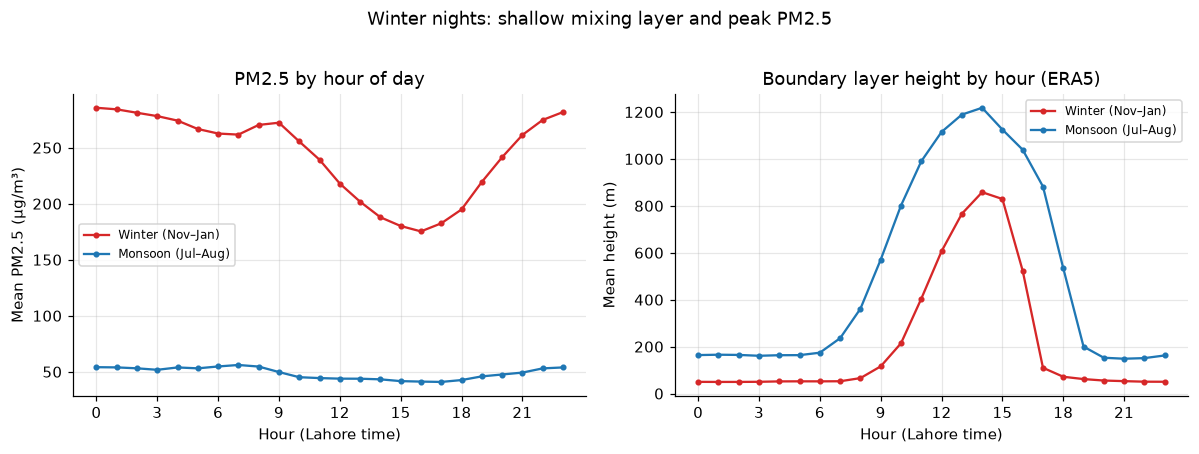

Winter: highest hour 0 286 | lowest hour 16 175


In [9]:
h = pd.read_csv(os.path.join(ROOT, "data/processed/us_consulate_pm25_hourly_clean.csv"))
h["t"] = pd.to_datetime(h["t"], utc=True).dt.tz_convert("Asia/Karachi")
h["hour"] = h.t.dt.hour; h["month"] = h.t.dt.month
wx = pd.read_csv(os.path.join(ROOT, "data/raw/openmeteo_era5_weather_hourly.csv"), parse_dates=["time"])
wx["hour"] = wx.time.dt.hour; wx["month"] = wx.time.dt.month
groups = {"Winter (Nov–Jan)": [11, 12, 1], "Monsoon (Jul–Aug)": [7, 8]}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for (name, ms), c in zip(groups.items(), ["tab:red", "tab:blue"]):
    ax[0].plot(h[h.month.isin(ms)].groupby("hour").pm25.mean(), color=c, marker="o", ms=3, label=name)
    ax[1].plot(wx[wx.month.isin(ms)].groupby("hour").boundary_layer_height.mean(), color=c, marker="o", ms=3, label=name)
ax[0].set(title="PM2.5 by hour of day", xlabel="Hour (Lahore time)", ylabel="Mean PM2.5 (µg/m³)")
ax[1].set(title="Boundary layer height by hour (ERA5)", xlabel="Hour (Lahore time)", ylabel="Mean height (m)")
for a in ax: a.legend(fontsize=8); a.set_xticks(range(0, 24, 3))
fig.suptitle("Winter nights: shallow mixing layer and peak PM2.5", y=1.02)
fig.tight_layout(); fig.savefig(os.path.join(VIS, "fig04_diurnal_cycle_blh.png"), bbox_inches="tight"); plt.show()
wint = h[h.month.isin([11,12,1])].groupby("hour").pm25.mean()
print("Winter: highest hour", wint.idxmax(), round(wint.max()), "| lowest hour", wint.idxmin(), round(wint.min()))

## 6. Weather vs PM2.5 (Spearman rank correlation)
I use Spearman correlation because PM2.5 is very skewed and the relationships are not linear. I compute it for (a) the whole year, which mixes the seasonal cycle in, and (b) only the core smog season (Nov–Jan), which asks: *within* winter, which conditions go with worse days?

In [10]:
weather_cols = {"temp_mean_c": "Mean temperature", "temp_min_c": "Minimum temperature", "temp_range_c": "Day–night temp. range",
                "rh_mean_pct": "Relative humidity", "wind_speed_mean_kmh": "Wind speed", "precip_mm": "Rainfall",
                "pressure_mean_hpa": "Surface pressure", "blh_mean_m": "Boundary layer height (daily mean)",
                "blh_night_mean_m": "Boundary layer height (night)", "fires_punjab_region_total": "Fire detections (Punjab region)"}
winter_mask = df.index.month.isin([11, 12, 1])
corr = pd.DataFrame({
    "All year": df[list(weather_cols)].corrwith(pm, method="spearman"),
    "Nov–Jan only": df.loc[winter_mask, list(weather_cols)].corrwith(pm[winter_mask], method="spearman"),
}).rename(index=weather_cols).round(2)
corr

,All year,Nov–Jan only
Mean temperature,-0.65,-0.03
Minimum temperature,-0.71,-0.12
Day–night temp. range,0.37,0.22
Relative humidity,0.17,0.17
Wind speed,-0.48,-0.50
Rainfall,-0.47,-0.20
Surface pressure,0.71,0.13
Boundary layer height (daily mean),-0.64,-0.41
Boundary layer height (night),-0.69,-0.65
Fire detections (Punjab region),0.34,0.06


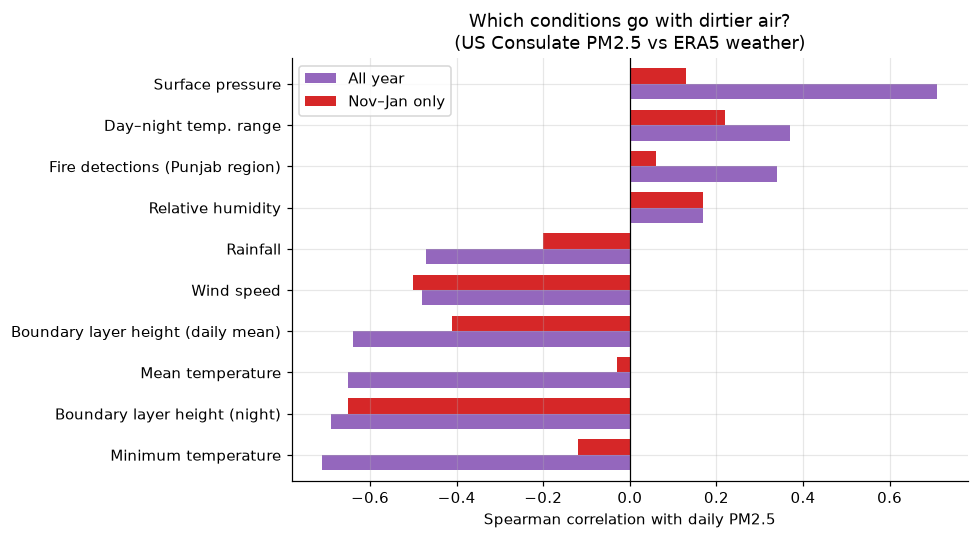

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
corr.sort_values("All year").plot.barh(ax=ax, color=["tab:purple", "tab:red"], width=0.75)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Spearman correlation with daily PM2.5")
ax.set_title("Which conditions go with dirtier air?\n(US Consulate PM2.5 vs ERA5 weather)")
fig.tight_layout(); fig.savefig(os.path.join(VIS, "fig05_weather_correlations.png")); plt.show()

**Reading this chart:** over the whole year, cold, high-pressure days with a low boundary layer, little wind and no rain are the polluted ones. Inside the winter season, temperature by itself stops mattering much (all winter days are cold), but **night-time boundary-layer height** and **wind speed** still separate bad days from very bad days. That points to *ventilation* — how much room and wind the air has to dilute pollution — as the key meteorological control.

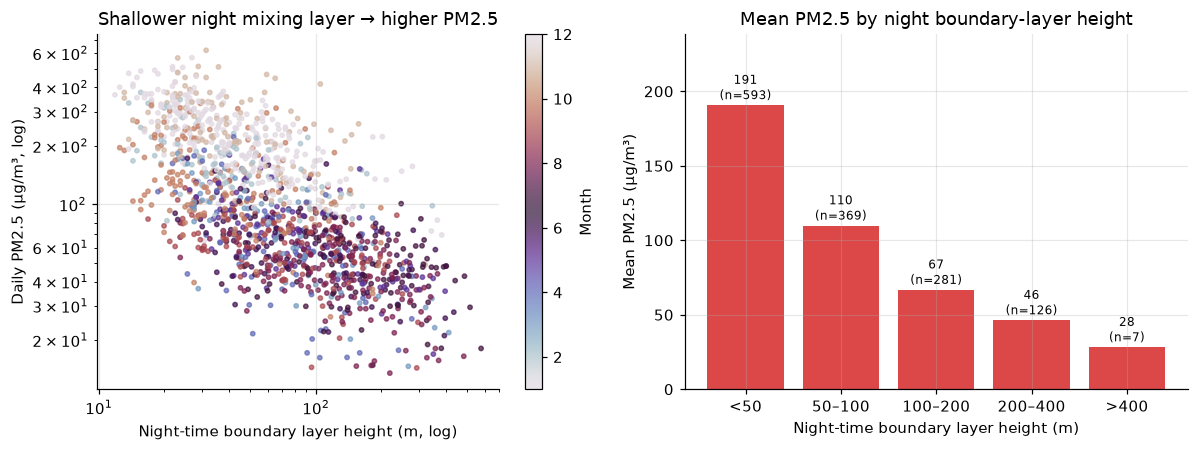

,mean,count
blh_night_mean_m,,
<50,190.7,593
50–100,109.8,369
100–200,66.7,281
200–400,46.3,126
>400,28.2,7


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sub = df[["pm25_consulate", "blh_night_mean_m", "wind_speed_mean_kmh"]].dropna()
sc = ax[0].scatter(sub.blh_night_mean_m, sub.pm25_consulate, c=sub.index.month, cmap="twilight", s=8, alpha=0.7)
ax[0].set(xscale="log", yscale="log", xlabel="Night-time boundary layer height (m, log)", ylabel="Daily PM2.5 (µg/m³, log)",
          title="Shallower night mixing layer → higher PM2.5")
plt.colorbar(sc, ax=ax[0], label="Month")
bins = pd.cut(df.blh_night_mean_m, [0, 50, 100, 200, 400, 3000], labels=["<50", "50–100", "100–200", "200–400", ">400"])
g = pm.groupby(bins, observed=True).agg(["mean", "count"])
ax[1].bar(g.index.astype(str), g["mean"], color="tab:red", alpha=0.85)
for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
    ax[1].text(i, m + 4, f"{m:.0f}\n(n={n})", ha="center", fontsize=8)
ax[1].set(xlabel="Night-time boundary layer height (m)", ylabel="Mean PM2.5 (µg/m³)", title="Mean PM2.5 by night boundary-layer height")
ax[1].set_ylim(0, g["mean"].max() * 1.25)
fig.tight_layout(); fig.savefig(os.path.join(VIS, "fig06_boundary_layer_vs_pm25.png")); plt.show()
g.round(1)

In [13]:
wbins = pd.cut(df.wind_speed_mean_kmh, [0, 4, 6, 8, 10, 40], labels=["<4", "4–6", "6–8", "8–10", ">10"])
pd.DataFrame({"all year": pm.groupby(wbins, observed=True).mean(),
              "Nov–Jan": pm[winter_mask].groupby(wbins[winter_mask], observed=True).mean()}).round(1).rename_axis("daily mean wind (km/h)")

,all year,Nov–Jan
daily mean wind (km/h),,
<4,284.5,305.5
4–6,177.9,278.0
6–8,127.0,224.0
8–10,93.3,170.9
>10,68.8,134.1


## 7. Fire season overlay (NASA FIRMS, MODIS)
Satellite fire detections in the Punjab region (Pakistani + Indian Punjab, box 29.5–32.6°N, 72.0–76.9°E) peak twice a year: **April–May** (wheat harvest) and **October–November** (rice residue burning). Only the autumn peak lines up with the PM2.5 rise — in spring the boundary layer is deep and hot, so smoke disperses. Again: this overlap is *consistent with* a crop-burning contribution in autumn but does not measure its size.

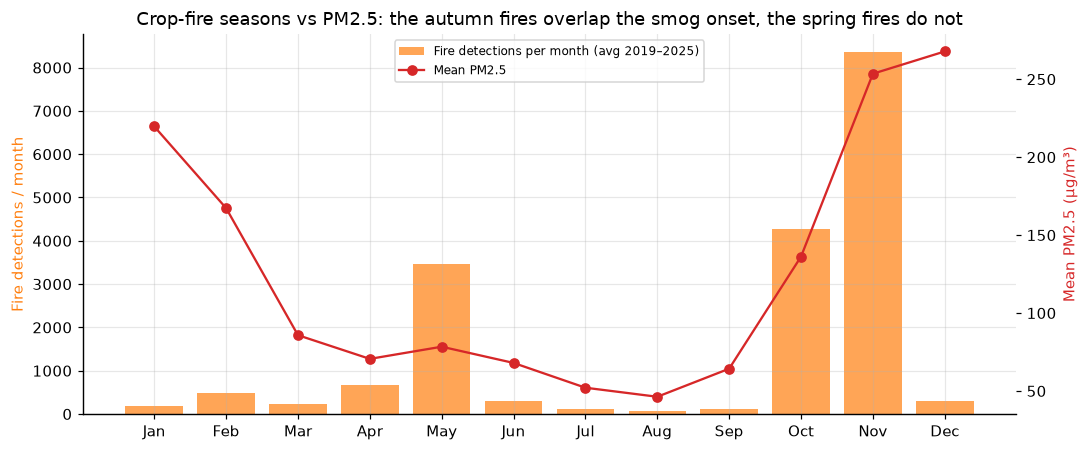

Oct–Nov Spearman r, PM2.5 vs same-day fires: 0.29
Oct–Nov Spearman r, PM2.5 vs fires 1 day earlier: 0.41


,all fire detections,Oct–Nov detections
date,,
2019,19579,11999
2020,23709,19347
2021,27602,22180
2022,20795,12886
2023,15044,10757
2024,12635,6032
2025,10773,5243


In [14]:
fires = df.fires_punjab_region_total
fm = fires[fires.index.year <= 2025].groupby(fires[fires.index.year <= 2025].index.month).sum() / 7  # avg per year (2019–2025)
fig, ax1 = plt.subplots(figsize=(10, 4.2))
ax1.bar(range(1, 13), fm.values, color="tab:orange", alpha=0.7, label="Fire detections per month (avg 2019–2025)")
ax1.set_ylabel("Fire detections / month", color="tab:orange")
ax2 = ax1.twinx()
ax2.plot(range(1, 13), monthly["mean"].values, "o-", color="tab:red", label="Mean PM2.5")
ax2.set_ylabel("Mean PM2.5 (µg/m³)", color="tab:red"); ax2.grid(False)
ax1.set_xticks(range(1, 13)); ax1.set_xticklabels(months)
ax1.set_title("Crop-fire seasons vs PM2.5: the autumn fires overlap the smog onset, the spring fires do not")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper center")
fig.tight_layout(); fig.savefig(os.path.join(VIS, "fig07_fire_season_overlay.png")); plt.show()

on = df.index.month.isin([10, 11])
print("Oct–Nov Spearman r, PM2.5 vs same-day fires:", round(df.loc[on, "fires_punjab_region_total"].corr(pm[on], method="spearman"), 2))
print("Oct–Nov Spearman r, PM2.5 vs fires 1 day earlier:", round(df["fires_punjab_region_total"].shift(1)[on].corr(pm[on], method="spearman"), 2))
yearly_fires = fires[fires.index.year <= 2025].groupby(fires[fires.index.year <= 2025].index.year).sum()
yearly_oct_nov = fires[(fires.index.year <= 2025) & on].groupby(fires[(fires.index.year <= 2025) & on].index.year).sum()
pd.DataFrame({"all fire detections": yearly_fires, "Oct–Nov detections": yearly_oct_nov}).astype(int)

## 8. How do the three PM2.5 sources compare?
This matters for the next step (forecasting) and for anyone re-using the data.

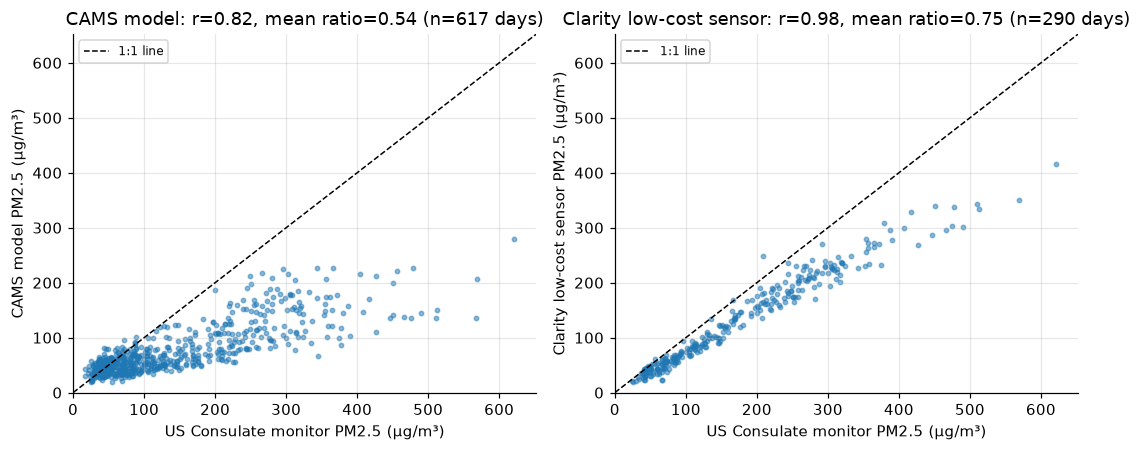

In [15]:
pair = df[["pm25_consulate", "pm25_cams_model"]].dropna()
pair2 = df[["pm25_consulate", "pm25_clarity_sensor"]].dropna()
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, p, col, name in [(ax[0], pair, "pm25_cams_model", "CAMS model"), (ax[1], pair2, "pm25_clarity_sensor", "Clarity low-cost sensor")]:
    a.scatter(p.pm25_consulate, p[col], s=8, alpha=0.5)
    lim = max(p.max()) * 1.05
    a.plot([0, lim], [0, lim], "k--", lw=1, label="1:1 line")
    r = p.corr().iloc[0, 1]; ratio = p[col].mean() / p.pm25_consulate.mean()
    a.set(xlim=(0, lim), ylim=(0, lim), xlabel="US Consulate monitor PM2.5 (µg/m³)", ylabel=f"{name} PM2.5 (µg/m³)",
          title=f"{name}: r={r:.2f}, mean ratio={ratio:.2f} (n={len(p)} days)")
    a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(VIS, "fig08_data_source_comparison.png")); plt.show()

**Takeaway:** the CAMS model follows the *timing* of pollution well (r ≈ 0.8) but underestimates the *level* by roughly half in Lahore, and the low-cost sensor tracks the monitor closely but reads low on the worst days. So the reference monitor is the ground truth for this project, and any other series must be calibrated before being used in its place.

## 9. Summary of preliminary findings
See `research/preliminary_findings.md` for the written report. Key points:
- Lahore's PM2.5 is far above the WHO guideline on most days of the year, and extreme in Nov–Jan.
- There is a strong, repeatable seasonal cycle (winter ≈ 4–5× the monsoon level).
- Cold, still, high-pressure days with a shallow (night-time) boundary layer are the most polluted ones — consistent with the temperature-inversion explanation in the literature.
- The autumn crop-fire peak overlaps the smog onset; the spring peak does not cause comparable smog, showing that meteorology decides how much emitted pollution builds up.
- Next-day PM2.5 is highly persistent (lag-1 autocorrelation below), which is the starting point for forecasting in notebook 02.

In [16]:
print("Lag-1 autocorrelation of daily PM2.5:", round(pm.autocorr(1), 2))

Lag-1 autocorrelation of daily PM2.5: 0.87
